# Teste do Temporal Fusion Transformer: o mesmo corte da LSTM

A série já está em `dados/internacoes_mes_uf.parquet`. Este notebook não baixa arquivo do DATASUS.

O desenho é o mesmo do `teste_lstm_2026.ipynb`. Cada ponto é o número de AIHs normais (`IDENT` = 1) com data de internação naquele mês, no estado do hospital. O treino vai até dezembro de 2025. O teste é janeiro a julho de 2026. Agosto e setembro de 2026 ficam de fora: o lançamento desses meses ainda está incompleto, e a queda que eles mostram é de registro, não de assistência.

O Temporal Fusion Transformer (TFT) é um modelo de atenção feito para painel temporal. Ele lê o passado de cada estado, recebe o que já se sabe sobre o futuro (o calendário e o mesmo mês do ano anterior) e devolve os sete meses de 2026. A comparação é com a LSTM já ajustada e com a repetição do mesmo mês de 2025.

## 1. Montar a tabela mês por estado

O parquet tem `uf`, `mes` e `internacoes`. O `pivot` faz uma linha por mês e uma coluna por UF.

O índice começa em julho de 2008. Os arquivos existem desde janeiro daquele ano, mas uma internação costuma ser faturada meses depois da entrada. Os primeiros meses de 2008 ainda perdem internações lançadas em 2007. Começar em julho tira essa borda.

`treino` acaba em dezembro de 2025. `teste` é janeiro a julho de 2026. Agosto e setembro não entram no painel.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from lightning.pytorch import Trainer
from pytorch_forecasting import TemporalFusionTransformer, TimeSeriesDataSet
from pytorch_forecasting.data import GroupNormalizer
from pytorch_forecasting.metrics import QuantileLoss

from datasus import UFS

PASTA = Path("dados")
JANELA = 24
HORIZONTE = 7
SEMENTE = 42

torch.manual_seed(SEMENTE)
np.random.seed(SEMENTE)

serie = pd.read_parquet(PASTA / "internacoes_mes_uf.parquet")
painel = serie.pivot(index="mes", columns="uf", values="internacoes")
painel = painel.reindex(columns=list(UFS))
painel = painel.reindex(pd.date_range("2008-07-01", "2026-07-01", freq="MS"))

treino_largo = painel.loc[:"2025-12-01"]
teste = painel.loc["2026-01-01":"2026-07-01"]
print(f"Treino: {treino_largo.index.min():%Y-%m} a {treino_largo.index.max():%Y-%m} ({len(treino_largo)} meses)")
print(f"Teste:  {teste.index.min():%Y-%m} a {teste.index.max():%Y-%m} ({len(teste)} meses)")
print(f"Valores ausentes no teste: {int(teste.isna().sum().sum())}")


Treino: 2008-07 a 2025-12 (210 meses)
Teste:  2026-01 a 2026-07 (7 meses)
Valores ausentes no teste: 0


## 2. Formato longo e o que já se sabe sobre o futuro

O TFT não lê a tabela larga. Ele lê uma linha por estado e por mês, com um índice inteiro `time_idx` que conta os meses dentro de cada UF. O índice precisa ser consecutivo: um buraco seria um mês faltando.

Duas colunas descrevem o futuro e já podem ser preenchidas antes da previsão:

- `mes_sin` e `mes_cos` são o seno e o cosseno do mês do calendário. Janeiro de 2026 já se sabe que é janeiro.
- `mesmo_mes_ano_anterior` é a quantidade daquele estado doze meses antes. Para prever janeiro de 2026, janeiro de 2025 já aconteceu.

A primeira coluna exige doze meses de história. As linhas sem esse valor saem da tabela, e o que entra no modelo começa em julho de 2009. O teste não muda: a janela que prevê 2026 usa 2024 e 2025, que estão completos.

`internacoes` é a única coluna desconhecida no futuro. É o alvo.

In [14]:
longo = painel.stack().rename("internacoes").reset_index()
longo.columns = ["mes", "uf", "internacoes"]
longo = longo.sort_values(["uf", "mes"])
longo["mesmo_mes_ano_anterior"] = longo.groupby("uf")["internacoes"].shift(12)
longo = longo.dropna().reset_index(drop=True)
longo["time_idx"] = longo.groupby("uf").cumcount()
angulo = 2 * np.pi * longo["mes"].dt.month / 12
longo["mes_sin"] = np.sin(angulo)
longo["mes_cos"] = np.cos(angulo)

corte = int(longo.loc[longo["mes"] == "2025-12-01", "time_idx"].iloc[0])
print(f"Tabela do modelo: {longo['mes'].min():%Y-%m} a {longo['mes'].max():%Y-%m}")
print(f"Índice de dezembro de 2025: {corte}. Janeiro de 2026 começa em {corte + 1}.")


Tabela do modelo: 2009-07 a 2026-07
Índice de dezembro de 2025: 197. Janeiro de 2026 começa em 198.


## 3. O conjunto de janelas

`TimeSeriesDataSet` corta a tabela em janelas. Cada janela tem 24 meses de passado (`max_encoder_length`) e 7 meses de futuro (`max_prediction_length`). O comprimento não é sorteado: toda janela tem o mesmo tamanho da LSTM, para a comparação não misturar horizontes diferentes.

O conjunto de treino só recebe linhas com `time_idx` até dezembro de 2025. Uma janela de treino só existe se os sete meses de resposta cabem até esse corte. 2026 não entra na perda.

`GroupNormalizer` padroniza o alvo dentro de cada UF, com média e desvio calculados no treino. São Paulo e o Acre deixam de competir na mesma escala numérica. As variáveis conhecidas do futuro também são padronizadas pelo próprio conjunto de treino.

`predict=True` no conjunto de teste pede uma única janela por estado: a última da série. Como a série acaba em julho de 2026, essa janela é exatamente janeiro a julho de 2026, lendo os 24 meses anteriores.

In [15]:
treino = TimeSeriesDataSet(
    longo[longo.time_idx <= corte],
    time_idx="time_idx",
    target="internacoes",
    group_ids=["uf"],
    max_encoder_length=JANELA,
    min_encoder_length=JANELA,
    max_prediction_length=HORIZONTE,
    min_prediction_length=HORIZONTE,
    time_varying_known_reals=["mes_sin", "mes_cos", "mesmo_mes_ano_anterior"],
    time_varying_unknown_reals=["internacoes"],
    target_normalizer=GroupNormalizer(groups=["uf"]),
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,
    randomize_length=False,
)
previsao_ds = TimeSeriesDataSet.from_dataset(
    treino, longo, predict=True, stop_randomization=True
)
print(f"Janelas de treino: {len(treino):,}. Janelas de teste: {len(previsao_ds)}.")


Janelas de treino: 4,536. Janelas de teste: 27.


## 4. A rede e o ajuste

O TFT junta três peças.

O passado de 24 meses passa por uma seleção de variáveis e por uma LSTM, que resume a trajetória do estado. Uma atenção de várias cabeças olha de novo esses meses e decide quais pesam mais para o horizonte. O futuro conhecido, o calendário e o mesmo mês do ano anterior, entra direto no decodificador, sem ser tratado como incógnita. A saída é uma perda de quantis: em vez de um único número, a rede estima uma distribuição. O ponto usado na comparação é a mediana, o quantil 0,5.

A rede é pequena de propósito. São 27 séries mensais, não milhões de linhas. `hidden_size` 32 e uma cabeça de atenção bastam para este painel. O otimizador é o Adam, com taxa 0,001 e o gradiente cortado em 0,1 para a atenção não disparar. São 25 épocas no processador, sem seleção do melhor época pelo teste: 2026 só aparece depois do ajuste.

O aviso de que não há dataloader de validação é esperado. Não há validação no meio do treino, para o critério de parada não espiar 2026.

In [16]:
modelo = TemporalFusionTransformer.from_dataset(
    treino,
    learning_rate=1e-3,
    hidden_size=32,
    attention_head_size=1,
    dropout=0.1,
    hidden_continuous_size=16,
    loss=QuantileLoss(),
)
treinador = Trainer(
    max_epochs=25,
    accelerator="cpu",
    gradient_clip_val=0.1,
    enable_model_summary=False,
    logger=False,
    enable_checkpointing=False,
    enable_progress_bar=True,
    num_sanity_val_steps=0,
)
treinador.fit(
    modelo,
    train_dataloaders=treino.to_dataloader(train=True, batch_size=64, num_workers=0),
)


c:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
c:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


c:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\rich\live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.
c:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


c:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\loops\training_epoch_loo
p.py:500: ReduceLROnPlateau conditioned on metric val_loss which is not available but strict is set to `False`. 
Skipping learning rate update.

`Trainer.fit` stopped: `max_epochs=25` reached.


## 5. Prever janeiro a julho e medir o erro

`predict` devolve as internações já na escala original, uma linha por UF e sete colunas, uma por mês. `return_index=True` traz a UF de cada linha, porque a ordem do lote não é a ordem alfabética garantida na mão.

O MAE é a média do módulo da diferença, em internações por mês. O MAPE divide essa diferença pelo observado. Os dois são calculados em cada estado e depois resumidos pela média dos 27.

A LSTM comparada é a que já foi gravada em `dados/teste_2026_lstm.parquet`, no mesmo corte. A referência sem modelo repete janeiro a julho de 2025. Se o TFT não reduzir o erro dessas duas colunas, a atenção não melhorou nem a rede recorrente nem a repetição sazonal.

In [17]:
saida = modelo.predict(
    previsao_ds.to_dataloader(train=False, batch_size=64, num_workers=0),
    mode="prediction",
    return_index=True,
    trainer_kwargs={"logger": False, "enable_progress_bar": False},
)
valores = saida.output.detach().numpy()
tft = pd.DataFrame(index=teste.index, columns=list(UFS), dtype=float)
for i, uf in enumerate(saida.index["uf"]):
    tft[uf] = np.clip(valores[i], 0, None)
tft.to_parquet(PASTA / "teste_2026_tft.parquet")

lstm = pd.read_parquet(PASTA / "teste_2026_lstm.parquet").reindex(teste.index)
referencia = painel.shift(12).loc[teste.index]


def erro_por_estado(real: pd.DataFrame, estimativa: pd.DataFrame) -> pd.DataFrame:
    linhas = []
    for uf in real.columns:
        pares = pd.DataFrame({"real": real[uf], "est": estimativa[uf]}).dropna()
        diferenca = (pares["est"] - pares["real"]).abs()
        linhas.append(
            {
                "uf": uf,
                "mae": diferenca.mean(),
                "mape_%": (diferenca / pares["real"].clip(lower=1)).mean() * 100,
            }
        )
    return pd.DataFrame(linhas).set_index("uf")


comparacao = pd.concat(
    {
        "tft": erro_por_estado(teste, tft),
        "lstm": erro_por_estado(teste, lstm),
        "mesmo_mes_2025": erro_por_estado(teste, referencia),
    },
    axis=1,
)
print("Erro médio entre os estados, janeiro a julho de 2026")
print(comparacao.mean().round(1).to_string())
comparacao.round(1)


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


Erro médio entre os estados, janeiro a julho de 2026
tft             mae       1727.5
                mape_%      10.1
lstm            mae       2523.7
                mape_%      11.6
mesmo_mes_2025  mae       1760.6
                mape_%       9.9


c:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


tft           lstm        mesmo_mes_2025       
       mae mape_%     mae mape_%            mae mape_%
uf                                                    
AC   645.1   17.3   722.1   19.2          569.7   15.5
AL   538.2    3.5  1180.9    7.8          841.7    5.7
AM  1646.3    7.3   500.2    2.1         1581.0    7.0
AP   536.2    9.6   505.8    9.1          616.3   11.1
BA  3378.9    4.3  3888.3    5.0         3456.0    4.3
CE  1237.2    2.4  1300.8    2.6         1843.7    3.6
DF   952.3    4.9  1015.9    5.0          876.1    4.3
ES  1081.3    4.3  1379.6    5.5         1240.0    4.8
GO  1564.8    4.1  1858.3    4.8         1007.3    2.6
MA  3596.6    9.2  4528.9   11.6         2980.6    7.6
MG  3686.1    2.7  9990.4    7.3         4552.6    3.3
MS  1421.8    9.1  1009.8    6.1         1445.1    9.2
MT  1139.5    4.8  3096.1   13.6          808.3    3.5
PA  1537.8    3.2  1788.3    3.8         1960.0    4.1
PB   909.2    4.3   995.6    4.6          801.0    3.6
PE  1199.5    2.1  3162.1    5.4         1424.7    2.4
PI   854.3    4.7   981.8    5.2          531.7    2.9
PR  3052.3    3.3  4318.6    4.6         2781.9    3.0
RJ  3060.4    4.0  3770.3    4.8         3632.7    4.6
RN   761.2    4.4   814.3    4.5          922.1    5.2
RO  1146.6   12.4  1551.1   16.4         1511.1   15.7
RR  1113.2  124.6  1066.6  125.5          988.9  118.4
RS  2059.3    2.8  2623.2    3.6         3148.3    4.2
SC  2658.1    4.5  8152.9   13.8         1768.1    3.0
SE   695.9    7.1   964.2    9.2          601.0    6.1
SP  5550.3    2.3  6232.1    2.5         4981.6    2.0
TO   619.1    8.5   742.9   10.0          664.6    8.5

## 6. Ler o gráfico

Quatro estados, de janeiro de 2024 a julho de 2026. Azul é o observado. Laranja é o TFT. Verde é a LSTM do outro notebook. A tracejada é o mesmo mês de 2025.

O gráfico para em julho. O trecho que vale como teste é 2026. O azul de 2024 e 2025 é contexto: a rede já viu esses meses no treino. Onde a laranja cola na tracejada, o TFT quase repetiu o ano anterior. Onde ela se aproxima mais do azul do que a tracejada e a verde, a atenção corrigiu a sazonalidade na direção certa.

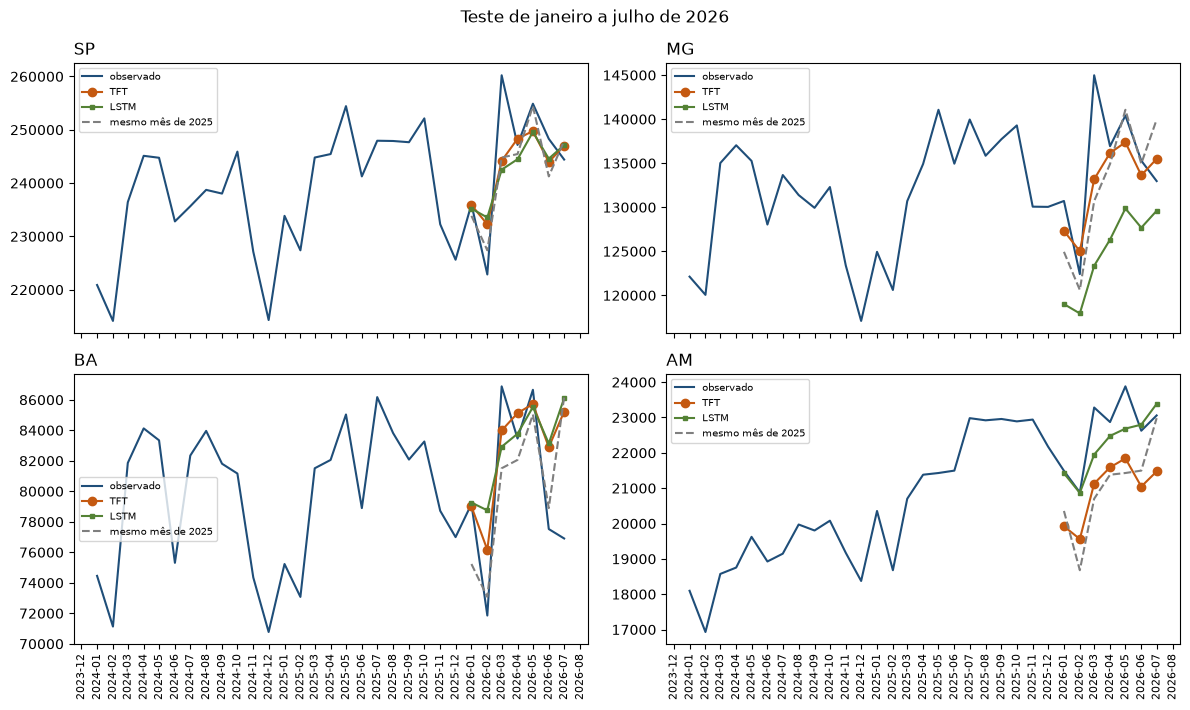

In [18]:
import matplotlib.dates as mdates

fig, eixos = plt.subplots(2, 2, figsize=(12, 7.2), sharex=True)
historia = painel.loc["2024-01-01":]
for eixo, uf in zip(eixos.ravel(), ["SP", "MG", "BA", "AM"]):
    eixo.plot(historia.index, historia[uf], color="#1f4e79", label="observado")
    eixo.plot(tft.index, tft[uf], color="#c45911", marker="o", label="TFT")
    eixo.plot(lstm.index, lstm[uf], color="#548235", marker="s", markersize=3, label="LSTM")
    eixo.plot(
        referencia.index,
        referencia[uf],
        color="#7f7f7f",
        linestyle="--",
        label="mesmo mês de 2025",
    )
    eixo.set_title(uf, loc="left")
    eixo.legend(fontsize=7)
eixos[0, 0].xaxis.set_major_locator(mdates.MonthLocator())
eixos[0, 0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
for eixo in eixos.ravel():
    eixo.tick_params(axis="x", labelrotation=90, labelsize=8)
fig.suptitle("Teste de janeiro a julho de 2026")
fig.tight_layout()
fig.savefig(PASTA / "teste_2026_tft.png", dpi=120, bbox_inches="tight")
plt.show()
